# T08 — Touch and step voltage assessment

A fault current that flows into an earthing system raises its
potential; people standing nearby bridge part of that potential
difference with their bodies. This tutorial computes the touch and
step voltages around a substation earthing grid, compares them with
the permissible values of EN 50522:2022, and shows which engine to use
for field quantities close to a grid.

**You will learn**

- the definitions of earth potential rise, touch voltage and step
  voltage, and how `groundfield` places the feet;
- the touch-voltage *envelope* around an electrode, and when to sample
  the inside of a grid;
- touch voltages at *touch points*, the accessible metal parts such as a
  fence bonded to the grid;
- why the image backend is fine for impedances but not for touch and
  step voltages next to a grid, and what to use instead;
- EN 50522's permissible touch voltage $U_{Tp}(t_f)$, also for an earth
  fault that is not cleared, and the prospective value with additional
  resistances;
- the true-RMS touch voltage of a fault current with harmonics.

Runtime: a few seconds.

## Definitions

With the fault current $I_E$ that flows into the earthing system and
its impedance $Z_E$, the **earth potential rise** is
$U_E = Z_E I_E$. A person who touches an earthed part while standing
on the surface at a distance of 1 m bridges the **touch voltage**

$$
U_T = \varphi_E - \varphi(\text{foot}),
$$

and a person walking near the electrode bridges the **step voltage**
between two points 1 m apart, $U_S = \varphi(\mathbf p_1) -
\varphi(\mathbf p_2)$. These are the *prospective* values (no body
current flowing); EN 50522 relates them to the permissible body
voltage through the fault duration $t_f$ and the resistances of
hands, feet, shoes and surface layer.

The touched parts are the accessible metal parts above ground. Where
they are known, `gf.touch_voltage_at_part` puts the feet on the circle
of radius `distance` (1 m) around a part bonded to an electrode or a
junction. Where they are not, `gf.touch_voltage` puts the feet
`distance` from the nearest wire of the electrode's footprint, on the
side given by `direction`, and `gf.touch_voltage_envelope` walks around
the whole footprint. The envelope samples nothing inside the footprint
by default, because there usually stands the station, the house or the
mast. A substation yard is different: people walk over the grid, and
`interior="meshes"` also samples the centres of the meshes (the *mesh
voltage* of IEEE Std 80).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf
from groundfield.references import ieee80

print("groundfield", gf.__version__)

RHO = 100.0  # Ohm m
I_FAULT = 150.0  # A, the part of the fault current that flows into this grid


def grid_world(current=I_FAULT):
    # Substation grid 20 m x 20 m, 4 x 4 meshes, at 0.5 m depth.
    world = gf.create_world(soil=gf.HomogeneousSoil(rho=RHO))
    gf.create_electrode(
        world,
        "grid_mesh",
        name="grid",
        corner=(0.0, 0.0, 0.5),
        size=(20.0, 20.0),
        n_x=4,
        n_y=4,
    )
    gf.create_source(world, attached_to="grid", magnitude=current)
    return world


world = grid_world()

groundfield 2026.11.0


## The grid resistance: two engines and IEEE Std 80

Before looking at the field around the grid we check its resistance
three ways: the image backend (one uniform leakage current per
straight wire — each line of the grid carries its own current per
metre, uniform along it), the `mom` backend (a separate current on
every segment, so the current can also crowd along each wire towards
the edges and corners) and Sverak's formula
of IEEE Std 80 (Eq. 57, an empirical closed form for grids),

$$
R_g = \rho\left[\frac{1}{L_T} + \frac{1}{\sqrt{20A}}\left(1 +
\frac{1}{1 + h\sqrt{20/A}}\right)\right].
$$

In [2]:
result_image = gf.create_engine(backend="image", segment_length=0.5).solve(world)
result_mom = gf.create_engine(backend="mom", segment_length=0.5).solve(world)
z_image = result_image.input_impedance()[0].real
z_mom = result_mom.input_impedance()[0].real
z_sverak = ieee80.grid_resistance_sverak(
    RHO, total_conductor_length=10 * 20.0, area=400.0, depth=0.5
)

print(f"image:             R = {z_image:.4f} Ohm")
print(
    f"mom:               R = {z_mom:.4f} Ohm ({z_image / z_mom - 1:+.1%} image vs mom)"
)
print(f"IEEE 80 (Sverak):  R = {z_sverak:.4f} Ohm ({z_sverak / z_mom - 1:+.1%} vs mom)")
print(
    f"earth potential rise U_E = {z_mom * I_FAULT:.1f} V at I_E = {I_FAULT:.0f} A (mom)"
)

image:             R = 2.3735 Ohm
mom:               R = 2.3473 Ohm (+1.1% image vs mom)
IEEE 80 (Sverak):  R = 2.6236 Ohm (+11.8% vs mom)
earth potential rise U_E = 352.1 V at I_E = 150 A (mom)


In [3]:
assert abs(z_image / z_mom - 1.0) < 0.06
assert abs(z_sverak / z_mom - 1.0) < 0.15  # an empirical formula

## Touch voltages around the grid

The grid is an open-air substation yard, so we ask for the mesh centres
as well (`interior="meshes"`) and evaluate the envelope with both
engines. The image result triggers a `UniformCurrentFieldWarning`; we
record it and print it once below.

In [4]:
envelope = {}
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for name, res in (("image", result_image), ("mom", result_mom)):
        angles, u_t, feet = gf.touch_voltage_envelope(
            res, world, electrode="grid", interior="meshes", return_points=True
        )
        envelope[name] = (np.abs(u_t), feet)
caveat = [w for w in caught if issubclass(w.category, gf.UniformCurrentFieldWarning)]
print(f"{len(caveat)} warning:", caveat[0].message)

for name, (u_t, feet) in envelope.items():
    k = int(np.argmax(u_t))
    print(
        f"{name:5s}: largest touch voltage {u_t[k]:6.1f} V at x = {feet[k, 0]:5.1f} m, y = {feet[k, 1]:5.1f} m"
    )
# The envelope lists the feet outside the grid first (24 directions and nine
# feet on the arc around each corner), then the mesh centres.
n_outside = len(gf.touch_voltage_envelope(result_mom, world, electrode="grid")[1])
print(f"largest mesh-centre value (mom): {envelope['mom'][0][n_outside:].max():.1f} V")

1 warning: touch_voltage_envelope: uniform-current backend 'image' within 5 m of a grid, mesh, star, strip, open polyline or bonded multi-electrode cluster: the surface potential is impedance-grade (against 'mom': 20 m grid corner touch 1 m outside +6 %, step from 1 m to 2 m outside -8 %, step from the point above the corner 1 m outwards -11 %; 4-arm star beyond a tip touch +8 %, step -9 %). Use backend='mom' for field-grade touch and step voltages.
image: largest touch voltage  149.6 V at x =  20.7 m, y =  20.7 m
mom  : largest touch voltage  140.7 V at x =  20.7 m, y =  20.7 m
largest mesh-centre value (mom): 79.6 V


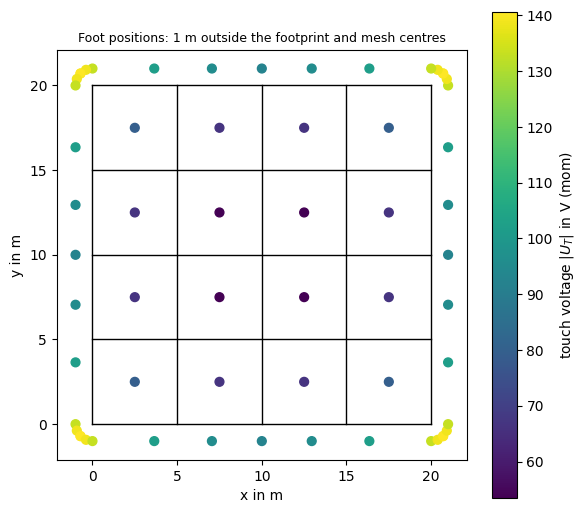

In [5]:
u_mom, feet = envelope["mom"]
fig, ax = plt.subplots(figsize=(6.0, 5.4))
for k in range(5):  # the grid wires
    ax.plot([0, 20], [5 * k, 5 * k], "k-", lw=1)
    ax.plot([5 * k, 5 * k], [0, 20], "k-", lw=1)
sc = ax.scatter(feet[:, 0], feet[:, 1], c=u_mom, cmap="viridis", s=40, zorder=3)
fig.colorbar(sc, ax=ax, label=r"touch voltage $|U_T|$ in V (mom)")
ax.set_aspect("equal")
ax.set_xlabel("x in m")
ax.set_ylabel("y in m")
ax.set_title("Foot positions: 1 m outside the footprint and mesh centres", fontsize=9)
fig.tight_layout()

In [6]:
assert len(caveat) == 1
u_image = envelope["image"][0]
assert (
    u_image.max() > u_mom.max()
)  # uniform current overestimates the touch voltage here

## Why the two engines differ near a grid

For the *impedance* the uniform-current ansatz of the image family is
accurate to a few percent. For the *field next to* a grid it is not:
in reality the current per metre also grows along each wire towards
its ends, so the corners carry the most and the potential falls off
more steeply at the edge. The image backend gives every wire line of
the grid its own current but keeps it uniform along the line, which
overestimates the touch voltage at the corner (+6 % here) and
underestimates the step voltage there (−8 %) — the second error is not on the safe side. The
warning says so, and recommends `backend="mom"` for field-grade
touch and step voltages near grids, meshes, stars, strips, open
polylines and bonded clusters. Rings, rods and closed loops are not
affected.

The profile along the diagonal through the corner shows the effect:

image: step voltage 1 m -> 2 m outside the corner: 26.4 V
mom  : step voltage 1 m -> 2 m outside the corner: 28.6 V


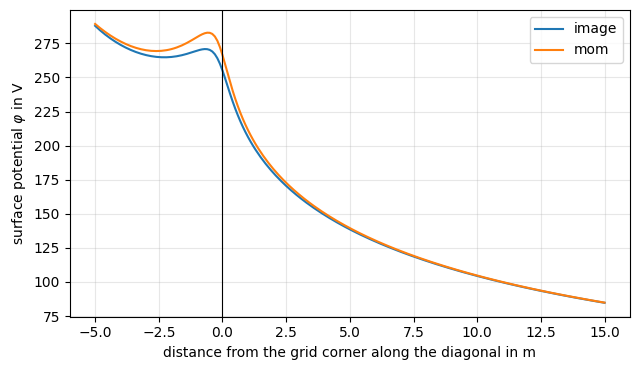

In [7]:
s = np.linspace(-5.0, 15.0, 201)  # m along the diagonal, 0 = grid corner (20, 20)
diagonal = np.column_stack([20 + s / np.sqrt(2), 20 + s / np.sqrt(2), np.zeros_like(s)])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", gf.UniformCurrentFieldWarning)
    profiles = {
        name: res.potential(diagonal).real
        for name, res in (("image", result_image), ("mom", result_mom))
    }

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for name, phi in profiles.items():
    ax.plot(s, phi, label=name)
ax.axvline(0.0, color="k", lw=0.8)
ax.set_xlabel("distance from the grid corner along the diagonal in m")
ax.set_ylabel(r"surface potential $\varphi$ in V")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

corner_out = (20 + 1 / np.sqrt(2), 20 + 1 / np.sqrt(2), 0.0)  # 1 m outside the corner
direction = (1 / np.sqrt(2), 1 / np.sqrt(2), 0.0)
step = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", gf.UniformCurrentFieldWarning)
    for name, res in (("image", result_image), ("mom", result_mom)):
        step[name] = abs(
            gf.step_voltage(res, position=corner_out, direction=direction, world=world)
        )
for name, u_s in step.items():
    print(f"{name:5s}: step voltage 1 m -> 2 m outside the corner: {u_s:.1f} V")

In [8]:
assert step["image"] < step["mom"]  # the non-conservative direction

## Touch points: a fence bonded to the grid

EN 50522 assesses the voltage between a *touched part* and the feet 1 m
away from it. A yard fence that is bonded to the grid carries the grid
potential to wherever it stands. With the fence 2 m outside the grid,
a person outside the fence stands 3 m from the grid, on a lower surface
potential than 1 m outside it. `gf.touch_voltage_at_part` takes the
post's position and the electrode it is bonded to; `directions` keeps
the feet on the side where people stand (`exclude` would remove the
feet inside the outlines of buildings, `n_angles` walks all round).

In [9]:
fence_posts = {  # position (m) and the outward direction
    "east side": ((22.0, 10.0), (1.0, 0.0)),
    "corner": ((22.0, 22.0), (1 / np.sqrt(2), 1 / np.sqrt(2))),
}
u_fence = {}
for name, (post, outward) in fence_posts.items():
    _, u = gf.touch_voltage_at_part(
        result_mom, world, position=post, bonded_to="grid", directions=[outward]
    )
    u_fence[name] = abs(u[0])
    print(
        f"fence post at the {name:9s}: {u_fence[name]:6.1f} V, feet 1 m outside the fence"
    )
print(f"envelope 1 m outside the grid (mom): {u_mom.max():6.1f} V")

fence post at the east side:  147.0 V, feet 1 m outside the fence
fence post at the corner   :  199.5 V, feet 1 m outside the fence
envelope 1 m outside the grid (mom):  140.7 V


In [10]:
assert (
    u_fence["corner"] > u_mom.max()
)  # the bonded fence carries the grid potential outwards

## EN 50522: the permissible touch voltage

EN 50522:2022 gives the permissible touch voltage $U_{Tp}$ as a
function of the fault duration $t_f$ up to 10 s (Figure 8, Table B.4);
`gf.permissible_touch_voltage_en50522` interpolates it. Beyond 10 s it
returns 80 V, the value the standard allows for current-flow durations
considerably longer than 10 s — also for an earth fault that is not
cleared (`math.inf`), as in a resonant-earthed network. With
additional resistances in the body circuit — shoes $R_{F1}$ and a
surface layer of resistivity $\rho_s$ — the permissible *prospective*
touch voltage of Annex B is

$$
U_{vTp} = U_{Tp}(t_f) + \frac{I_B(t_f)}{HF}\,\bigl(R_H + R_{F1} + 1.5\,\mathrm{m}^{-1}\,\rho_s\bigr),
$$

with the body current $I_B(t_f)$ of Table B.1
(`gf.permissible_prospective_touch_voltage_en50522`). We assess the
largest touch voltage of the yard — the `mom` envelope and the fence —
for a fault cleared after 0.5 s, without and with shoes (1000 Ω) on the
100 Ω·m soil, and for an earth fault that is not cleared.

largest touch voltage (mom, envelope and fence):      199.5 V
U_Tp(t_f = 0.5 s):                                      225.0 V
U_vTp with 1000 Ohm shoes on 100 Ohm m soil:           455.0 V
verdict: within U_Tp
U_Tp, earth fault not cleared:                         80.0 V
verdict if not cleared: exceeds U_Tp


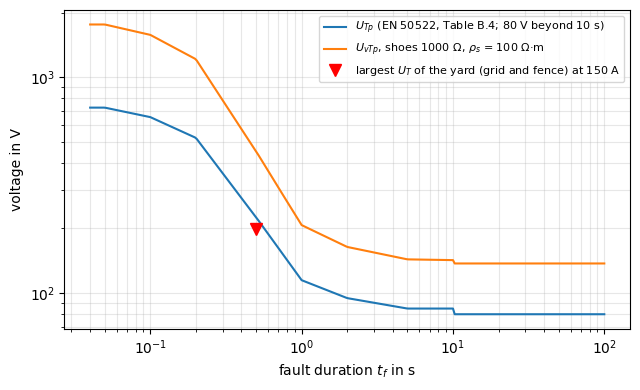

In [11]:
import math

T_F = 0.5  # s
u_t_max = max(u_mom.max(), *u_fence.values())
u_tp = gf.permissible_touch_voltage_en50522(T_F)
u_vtp = gf.permissible_prospective_touch_voltage_en50522(T_F, R_F1=1000.0, rho_s=RHO)
print(f"largest touch voltage (mom, envelope and fence):     {u_t_max:6.1f} V")
print(f"U_Tp(t_f = {T_F} s):                                     {u_tp:6.1f} V")
print(f"U_vTp with 1000 Ohm shoes on 100 Ohm m soil:          {u_vtp:6.1f} V")
print("verdict:", "within U_Tp" if u_t_max <= u_tp else "exceeds U_Tp")
u_tp_uncleared = gf.permissible_touch_voltage_en50522(math.inf)
print(f"U_Tp, earth fault not cleared:                       {u_tp_uncleared:6.1f} V")
print(
    "verdict if not cleared:",
    "within U_Tp" if u_t_max <= u_tp_uncleared else "exceeds U_Tp",
)

t = np.geomspace(0.04, 100.0, 300)
fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.loglog(
    t,
    [gf.permissible_touch_voltage_en50522(x) for x in t],
    label="$U_{Tp}$ (EN 50522, Table B.4; 80 V beyond 10 s)",
)
ax.loglog(
    t,
    [
        gf.permissible_prospective_touch_voltage_en50522(x, R_F1=1000.0, rho_s=RHO)
        for x in t
    ],
    label=r"$U_{vTp}$, shoes 1000 Ω, $\rho_s$ = 100 Ω·m",
)
ax.plot(
    [T_F],
    [u_t_max],
    "rv",
    ms=9,
    label=f"largest $U_T$ of the yard (grid and fence) at {I_FAULT:.0f} A",
)
ax.set_xlabel("fault duration $t_f$ in s")
ax.set_ylabel("voltage in V")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

In [12]:
assert abs(gf.permissible_touch_voltage_en50522(0.5) - 225.0) < 1e-9  # Table B.4
assert u_vtp > u_tp
assert gf.permissible_touch_voltage_en50522(math.inf) == 80.0  # not cleared (> 10 s)
assert u_t_max > u_tp_uncleared  # the yard would need more than its grid

## Fault currents with harmonics

In medium-voltage networks the residual earth-fault current is not a
pure 50 Hz sine. Because the field problem is linear, each harmonic
$k$ produces its own touch voltage $U_T(f_k)$ scaled with its current
$I_k$, and the true-RMS value is
$U_{T,\mathrm{rms}} = \sqrt{\sum_k |U_T(f_k)|^2}$.
`gf.touch_voltage_spectrum` takes a multi-frequency result and the
current per frequency. The grid alone has no inductive conductor, so
its touch voltage per ampere does not depend on frequency and the
result must equal the 50 Hz value scaled with the RMS current — a
simple check. With inductive cables (PEN, cable shields) the
harmonics see a different impedance and the scaling no longer holds.

In [13]:
spectrum = {
    50.0: 150.0,
    150.0: 25.0,
    250.0: 18.0,
    350.0: 9.0,
    550.0: 5.0,
}  # A, RMS per harmonic
world_1a = grid_world(current=1.0)
result_h = gf.create_engine(
    backend="mom", segment_length=0.5, frequencies=list(spectrum)
).solve(world_1a)
u_rms = gf.touch_voltage_spectrum(
    result_h, world_1a, electrode="grid", currents=spectrum
)
u_50_per_a = abs(gf.touch_voltage(result_h, world_1a, electrode="grid"))
i_rms = np.sqrt(sum(i**2 for i in spectrum.values()))
print(f"touch voltage at +x for 150 A at 50 Hz only: {u_50_per_a * 150.0:.2f} V")
print(f"true RMS over the spectrum:                  {u_rms:.2f} V")
print(f"50 Hz value per A x RMS current:             {u_50_per_a * i_rms:.2f} V")

touch voltage at +x for 150 A at 50 Hz only: 92.53 V
true RMS over the spectrum:                  94.68 V
50 Hz value per A x RMS current:             94.68 V


In [14]:
assert abs(u_rms / (u_50_per_a * i_rms) - 1.0) < 1e-9

EN 50522's limits are 50 Hz values; comparing a spectrum RMS with
$U_{Tp}$ ignores that the body tolerates more current at higher
frequencies (IEC 60479-2), which is on the safe side.

## Summary

- `touch_voltage_at_part` evaluates the touch voltage at a touch point,
  an accessible metal part bonded to an electrode or a junction.
- `touch_voltage`, `touch_voltage_envelope` and `step_voltage` place
  the feet relative to the electrode's footprint; for an open-air grid
  the envelope also samples the mesh centres (`interior="meshes"`).
- Use `backend="mom"` for touch and step voltages next to grids and
  other extended electrodes; the image backend warns where its
  uniform current is not field-grade.
- `permissible_touch_voltage_en50522` and
  `permissible_prospective_touch_voltage_en50522` give the EN 50522
  limits (80 V beyond 10 s and for an uncleared fault);
  `touch_voltage_spectrum` the true-RMS value of a harmonic fault
  current.

**Next:** [T09 — choosing an engine and checking
convergence](T09_choosing_an_engine_and_convergence.ipynb).